# Inspect SAM 3 tobacco predictions

Set a target image and a local original or trained SAM 3 checkpoint below, enable inference, and run all cells in the SAM 3 training environment. Reference-box mode also uses a local reference image and box. No annotations are needed; nothing is saved or downloaded.

Text mode uses the `tobacco plant` prompt from training and labeling. Reference-box mode experimentally reuses a visual prompt encoded from a separate image; it depends on SAM 3 internals and is not a validated cross-image API. Boxes are derived from predicted masks; predictions are not necessarily individual leaves. The saved output below predates this configuration.

In [7]:
from pathlib import Path

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'notebooks/reproduction.py').is_file())
IMAGE = ROOT / 'experiments/reproductions/tobacco-pseudolabels-03' / 'images/image_000003.png'
REFERENCE_IMAGE = ROOT / 'data/sam3_reference/image_000001.png'
REFERENCE_BOX_XYWH = (300, 165, 175, 180)
CHECKPOINT = Path('C:/Users/natsusa_aki/academic/sam3/dam3/sam3.pt')
# CHECKPOINT = ROOT / 'experiments/reproductions/sam3-simple-training-67/best.pt'
CONFIDENCE = 0.5
PROMPT = 'tobacco plant'
PROMPT_MODE = 'reference_box'
RUN_INFERENCE = True

In [8]:
def normalize_reference_box(box, image_size):
    import math

    if len(box) != 4:
        raise ValueError('REFERENCE_BOX_XYWH must contain x, y, width, and height.')
    x, y, width, height = box
    image_width, image_height = image_size
    if (not all(math.isfinite(value) for value in box) or
            image_width <= 0 or image_height <= 0 or x < 0 or y < 0 or
            width <= 0 or height <= 0 or
            x + width > image_width or y + height > image_height):
        raise ValueError('Reference box must be finite, positive, and inside the reference image.')
    return [(x + width / 2) / image_width, (y + height / 2) / image_height,
            width / image_width, height / image_height]


def predict_with_reference(processor, reference_image, target_image, box):
    from unittest.mock import patch

    normalized_box = normalize_reference_box(box, reference_image.size)
    reference_state = processor.set_image(reference_image)
    reference_state = processor.add_geometric_prompt(
        state=reference_state, box=normalized_box, label=True)
    model = processor.model
    prompt, prompt_mask, _ = model._encode_prompt(
        reference_state['backbone_out'], processor.find_stage,
        reference_state['geometric_prompt'])
    target_state = processor.set_image(target_image)
    target_state['geometric_prompt'] = model._get_dummy_prompt()

    def use_reference_prompt(backbone_out, find_input, geometric_prompt):
        return prompt, prompt_mask, backbone_out

    with patch.object(model, '_encode_prompt', new=use_reference_prompt):
        return processor._forward_grounding(target_state)

## Predict and display

This uses the checkpoint's training resolution, or 1008 for original weights, with CUDA/BF16. Set `PROMPT_MODE` to `reference_box` or `text` and choose a target `IMAGE`. The original example box belongs to the copied 480 × 352 reference image; change both when selecting another reference. Reference-box transfer is experimental, version-sensitive, and not evidence of accuracy. The overlay shows target masks and scores before label-generation processing.

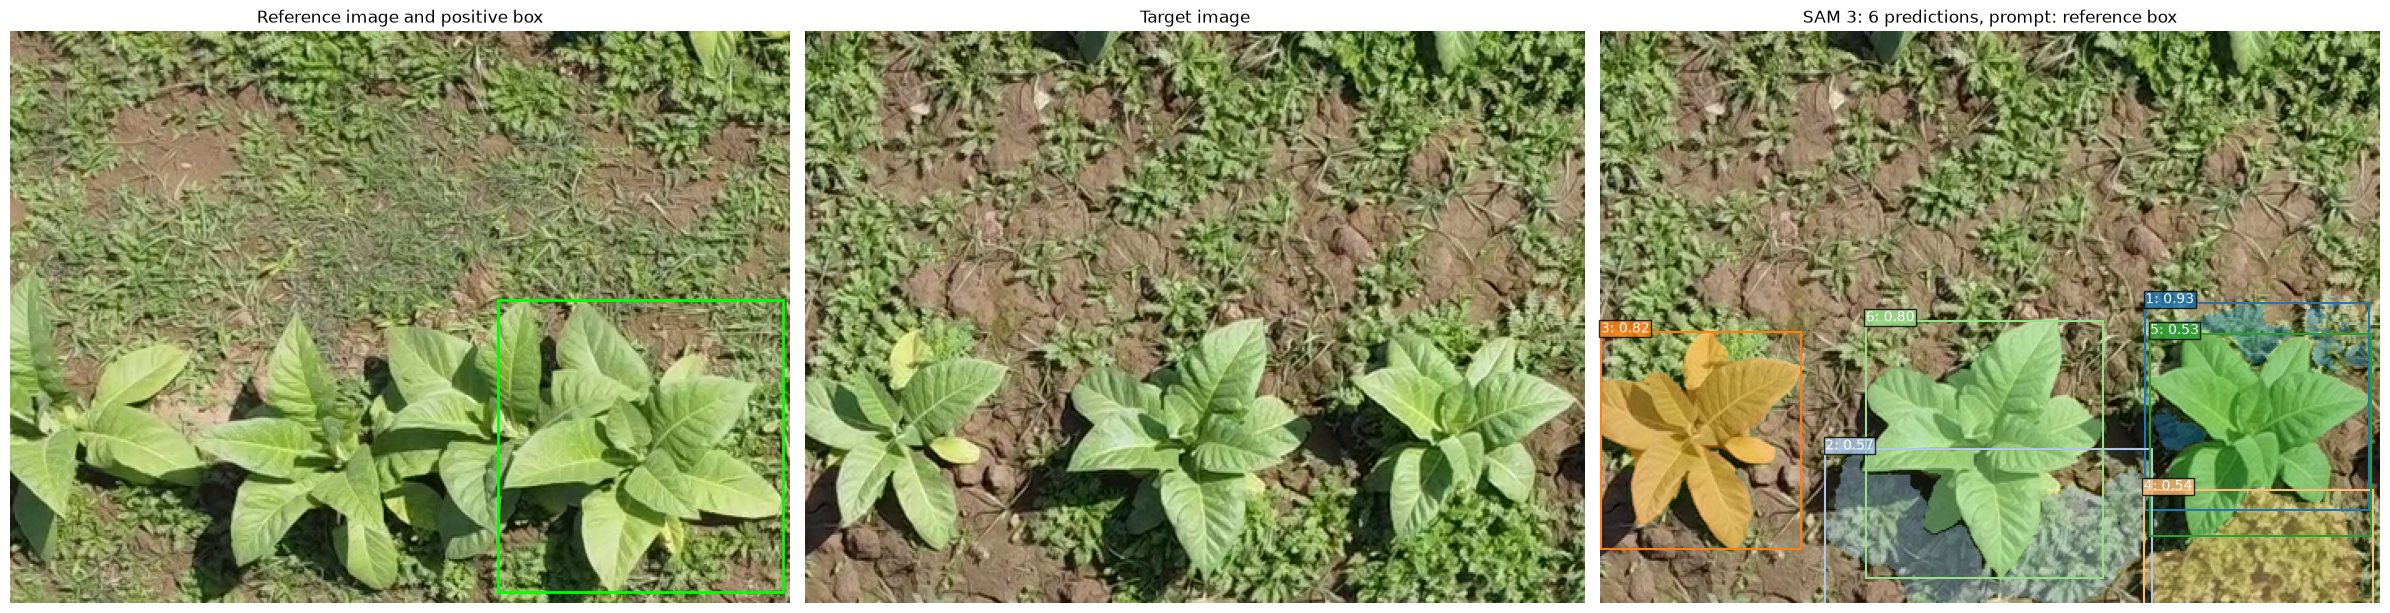

In [9]:
if RUN_INFERENCE:
    from collections import OrderedDict
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    import numpy as np
    from PIL import Image
    import torch
    from sam3.model_builder import build_sam3_image_model
    from sam3.model.sam3_image_processor import Sam3Processor

    if not IMAGE.is_file():
        raise FileNotFoundError(f'Image not found: {IMAGE}')
    if PROMPT_MODE not in ('reference_box', 'text'):
        raise ValueError("PROMPT_MODE must be 'reference_box' or 'text'.")
    if PROMPT_MODE == 'reference_box' and not REFERENCE_IMAGE.is_file():
        raise FileNotFoundError(f'Reference image not found: {REFERENCE_IMAGE}')
    if not CHECKPOINT.is_file():
        raise FileNotFoundError(f'SAM 3 checkpoint not found: {CHECKPOINT}')
    if not 0 <= CONFIDENCE <= 1:
        raise ValueError('CONFIDENCE must be between 0 and 1.')
    with Image.open(IMAGE) as source:
        image = source.convert('RGB')
    if PROMPT_MODE == 'reference_box':
        with Image.open(REFERENCE_IMAGE) as source:
            reference_image = source.convert('RGB')
        normalize_reference_box(REFERENCE_BOX_XYWH, reference_image.size)
    if not torch.cuda.is_available() or not torch.cuda.is_bf16_supported():
        raise RuntimeError('Inference requires a CUDA GPU with BF16 support.')

    payload = torch.load(CHECKPOINT, map_location='cpu', weights_only=True)
    if not isinstance(payload, dict):
        raise ValueError('Select a SAM 3 checkpoint containing model weights.')
    resolution = payload['options']['resolution'] if 'options' in payload else 1008
    state = payload.get('model', payload)
    if any(key.startswith('detector.') for key in state):
        state = {key.removeprefix('detector.'): value for key, value in state.items()
                 if key.startswith('detector.')}
    state = {key: value for key, value in state.items()
             if not key.startswith('backbone.vision_backbone.sam2_convs.')}
    model = build_sam3_image_model(device='cpu', eval_mode=True, load_from_HF=False,
                                   enable_segmentation=True, enable_inst_interactivity=False,
                                   compile=False)
    model.load_state_dict(state, strict=True)
    for block in model.backbone.vision_backbone.trunk.blocks:
        mlp = block.mlp
        block.mlp = torch.nn.Sequential(OrderedDict(
            (name, getattr(mlp, name)) for name in ('fc1', 'act', 'drop1', 'norm', 'fc2', 'drop2')))
    model = model.cuda().eval()
    processor = Sam3Processor(model, resolution=resolution, confidence_threshold=CONFIDENCE)

    with torch.inference_mode(), torch.autocast('cuda', dtype=torch.bfloat16):
        if PROMPT_MODE == 'reference_box':
            output = predict_with_reference(processor, reference_image, image, REFERENCE_BOX_XYWH)
        else:
            image_state = processor.set_image(image)
            output = processor.set_text_prompt(prompt=PROMPT, state=image_state)

    panel_count = 3 if PROMPT_MODE == 'reference_box' else 2
    fig, axes = plt.subplots(1, panel_count, figsize=(8 * panel_count, 8))
    if PROMPT_MODE == 'reference_box':
        axes[0].imshow(reference_image)
        x, y, width, height = REFERENCE_BOX_XYWH
        axes[0].add_patch(Rectangle((x, y), width, height, fill=False,
                                    edgecolor='lime', linewidth=2))
        axes[0].set_title('Reference image and positive box')
    target_axis, result_axis = axes[-2], axes[-1]
    target_axis.imshow(image)
    target_axis.set_title('Target image')
    result_axis.imshow(image)
    overlay = np.zeros((image.height, image.width, 4), dtype=np.float32)
    for index, (mask, score) in enumerate(zip(output['masks'], output['scores']), 1):
        mask = mask.detach().cpu().numpy().reshape(image.height, image.width).astype(bool)
        rows, columns = np.nonzero(mask)
        if not len(rows):
            continue
        color = plt.get_cmap('tab20')((index - 1) % 20)
        overlay[mask] = (*color[:3], 0.4)
        left, right, top, bottom = columns.min(), columns.max(), rows.min(), rows.max()
        result_axis.add_patch(Rectangle((left, top), right - left + 1, bottom - top + 1,
                                    fill=False, edgecolor=color, linewidth=1.5))
        result_axis.text(left, top, f'{index}: {float(score):.2f}', color='white',
                     bbox={'facecolor': color, 'alpha': 0.8, 'pad': 1})
    result_axis.imshow(overlay)
    count = len(output['scores'])
    prompt_description = 'reference box' if PROMPT_MODE == 'reference_box' else PROMPT
    result_axis.set_title(f'SAM 3: {count} predictions, prompt: {prompt_description}')
    for axis in axes:
        axis.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Set IMAGE, CHECKPOINT, and RUN_INFERENCE=True to inspect SAM 3 predictions.')